# Secure and Privacy-Preserving Federated Learning with Blockchain — MIMIC-III

## FINAL STRICT REPRODUCIBLE EXPERIMENT

This notebook implements a **true parameter-aggregation FedAvg experiment** with a custom hash-linked blockchain audit prototype.

### Publication-safety decisions
- `hadm_id` and identifier-like columns are excluded from predictors.
- If a patient identifier exists, it is used only for group-aware splitting and client partitioning.
- If no patient identifier exists, record-level splitting is used and the limitation is reported.
- The experiment is explicitly **retrospective encounter-level mortality classification**; no first-24/48-hour feature-availability claim is made.
- One `GLOBAL_POS_WEIGHT` is used by centralized training and all clients.
- FedAvg aggregates model parameters using sample-count weights, not client metrics.
- The blockchain is a custom Python/SHA-256/Proof-of-Work prototype, not Hyperledger Fabric/PBFT.
- Encryption is demonstrated, but the simulated server has decryption capability; this is not secure aggregation.

All primary metrics refer to class 1 = hospital mortality: Accuracy, Precision, Recall/Sensitivity, F1, Specificity, Balanced Accuracy, ROC-AUC, and PR-AUC.


In [63]:
# Kaggle/Colab installation cell
# Uncomment if packages are missing.

# !pip install -q cryptography scikit-learn pandas numpy matplotlib seaborn torch

In [64]:
import os, json, base64, copy, hashlib, random, warnings
from datetime import datetime
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from cryptography.fernet import Fernet
from sklearn.model_selection import train_test_split, StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score, balanced_accuracy_score, confusion_matrix, classification_report, roc_curve, precision_recall_curve)
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
warnings.filterwarnings('ignore')
SEED=42
np.random.seed(SEED); random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
DATA_PATH_CANDIDATES=['/kaggle/input/mimic3c/mimic3c.csv','/content/mimic3c.csv','./mimic3c.csv']
DATA_PATH=next((p for p in DATA_PATH_CANDIDATES if os.path.exists(p)),None)
TARGET='ExpiredHospital'
N_CLIENTS=5; N_ROUNDS=5; LOCAL_EPOCHS=3; BATCH_SIZE=256; LEARNING_RATE=1e-3; WEIGHT_DECAY=1e-4; HIDDEN_DIM=50
TEST_SIZE=0.20; VAL_SIZE=0.10; CLASSIFICATION_THRESHOLD=0.50; USE_GLOBAL_POS_WEIGHT=True
PATIENT_ID_CANDIDATES=['subject_id','subjectid','patient_id','patientid','SUBJECT_ID','PATIENT_ID']
IDENTIFIER_COLUMNS={'hadm_id','hadmid','subject_id','subjectid','patient_id','patientid','icustay_id','icustayid','row_id','rowid','index','Unnamed: 0'}
PREDICTION_SCOPE='retrospective_encounter_level_mortality_classification'
print('='*90); print('FINAL STRICT FEDERATED LEARNING + BLOCKCHAIN EXPERIMENT'); print('='*90)
print('Device:',DEVICE); print('Seed:',SEED); print('Prediction scope:',PREDICTION_SCOPE)


FINAL STRICT FEDERATED LEARNING + BLOCKCHAIN EXPERIMENT
Device: cuda
Seed: 42
Prediction scope: retrospective_encounter_level_mortality_classification


## 1. Load the MIMIC-III-derived dataset

The expected target is `ExpiredHospital`, where `1` denotes hospital mortality and `0` denotes survival.


In [65]:
if DATA_PATH is None:
    raise FileNotFoundError('mimic3c.csv not found. Update DATA_PATH or place it in: '+str(DATA_PATH_CANDIDATES))
df=pd.read_csv(DATA_PATH)
if TARGET not in df.columns: raise KeyError(f"Target column '{TARGET}' was not found.")
df=df.dropna(subset=[TARGET]).copy(); df[TARGET]=df[TARGET].astype(int)
if not set(df[TARGET].unique()).issubset({0,1}): raise ValueError(f'{TARGET} must be binary 0/1.')
print('Dataset path:',DATA_PATH); print('Dataset shape:',df.shape); print('\nTarget distribution:'); print(df[TARGET].value_counts().sort_index()); print(f"\nMortality prevalence: {df[TARGET].mean():.4%}"); display(df.head())


Dataset path: /kaggle/input/mimic3c/mimic3c.csv
Dataset shape: (58976, 28)

Target distribution:
ExpiredHospital
0    53122
1     5854
Name: count, dtype: int64

Mortality prevalence: 9.9261%


,hadm_id,gender,age,LOSdays,admit_type,admit_location,AdmitDiagnosis,insurance,religion,marital_status,...,NumMicroLabs,NumNotes,NumOutput,NumRx,NumProcEvents,NumTransfers,NumChartEvents,ExpiredHospital,TotalNumInteract,LOSgroupNum
0,100001,F,35,6.17,EMERGENCY,CLINIC REFERRAL/PREMATURE,DIABETIC KETOACIDOSIS,Private,PROTESTANT QUAKER,DIVORCED,...,0.65,0.05,5.19,14.91,1.13,0.65,398.70,0,493.89,2
1,100003,M,59,4.04,EMERGENCY,EMERGENCY ROOM ADMIT,UPPER GI BLEED,Private,NOT SPECIFIED,SINGLE,...,1.24,1.59,5.45,7.18,0.99,1.24,373.02,0,465.71,2
2,100006,F,48,12.04,EMERGENCY,EMERGENCY ROOM ADMIT,COPD FLARE,Private,NOT SPECIFIED,SINGLE,...,0.33,0.15,4.15,6.23,0.00,0.33,286.21,0,344.00,4
3,100007,F,73,7.29,EMERGENCY,EMERGENCY ROOM ADMIT,BOWEL OBSTRUCTION,Private,JEWISH,MARRIED,...,0.69,0.17,9.05,11.52,0.00,0.96,526.06,0,603.05,2
4,100009,M,60,4.88,EMERGENCY,TRANSFER FROM HOSP/EXTRAM,CORONARY ARTERY DISEASE,Private,CATHOLIC,MARRIED,...,0.61,0.34,16.19,25.00,2.87,2.05,554.92,0,679.84,2


In [66]:
## Data integrity and leakage audit

GROUP_COLUMN = next((c for c in PATIENT_ID_CANDIDATES if c in df.columns), None)
IDENTIFIER_LOWER = {x.lower() for x in IDENTIFIER_COLUMNS}
PRESENT_IDENTIFIER_COLUMNS = sorted([c for c in df.columns if c.lower() in IDENTIFIER_LOWER])
print('Detected patient grouping column:', GROUP_COLUMN)
print('Identifier-like columns detected:', PRESENT_IDENTIFIER_COLUMNS)
if GROUP_COLUMN is not None:
    missing_groups = int(df[GROUP_COLUMN].isna().sum())
    print(f"Missing values in '{GROUP_COLUMN}': {missing_groups:,}")
    if missing_groups > 0: raise ValueError(f"Patient grouping column '{GROUP_COLUMN}' contains missing values.")
    print('Unique patients/groups:', df[GROUP_COLUMN].nunique())
    print('Rows per group — median:', df.groupby(GROUP_COLUMN).size().median())
    print('Rows per group — max:', df.groupby(GROUP_COLUMN).size().max())
else:
    print('[WARNING] No patient identifier was found. Patient-level independence cannot be established.')
TEMPORAL_RISK_FEATURES=['LOSdays','NumOutput','NumRx','NumProcEvents','NumTransfers','NumChartEvents','TotalNumInteract']
present_temporal_risk=[c for c in TEMPORAL_RISK_FEATURES if c in df.columns]
print('\nFeatures requiring temporal interpretation:', present_temporal_risk)
print('Scope decision: retrospective encounter-level mortality classification; no first-24/48-hour claim.')
for col in PRESENT_IDENTIFIER_COLUMNS:
    print(f"{col}: unique={df[col].nunique(dropna=True):,}, rows={len(df):,}, duplicated_rows={df[col].duplicated(keep=False).sum():,}")


Detected patient grouping column: None
Identifier-like columns detected: ['hadm_id']
[WARNING] No patient identifier was found. Patient-level independence cannot be established.

Features requiring temporal interpretation: ['LOSdays', 'NumOutput', 'NumRx', 'NumProcEvents', 'NumTransfers', 'NumChartEvents', 'TotalNumInteract']
Scope decision: retrospective encounter-level mortality classification; no first-24/48-hour claim.
hadm_id: unique=58,976, rows=58,976, duplicated_rows=0


## 2. Deterministic feature engineering

Quantile-derived thresholds are fitted on training data only. The experiment is explicitly retrospective encounter-level classification and does not claim a first-24/48-hour prediction horizon.


In [67]:
TARGET='ExpiredHospital'
def add_deterministic_features(dataframe,q75_num_diagnosis=None,q90_chart_events=None):
    df=dataframe.copy()
    for c,fill in [('religion','UNKNOWN')]:
        if c in df.columns: df[c]=df[c].fillna(fill)
    for c in ['marital_status','AdmitDiagnosis']:
        if c in df.columns:
            mode=df[c].mode(); df[c]=df[c].fillna(mode.iloc[0] if len(mode) else 'UNKNOWN')
    if 'age' in df.columns:
        df['age_group']=pd.cut(df['age'],bins=[0,18,35,50,65,80,100,np.inf],labels=['pediatric','young_adult','adult','middle_aged','elderly','very_elderly','extreme_age'],include_lowest=True)
    if 'LOSdays' in df.columns:
        df['los_category']=pd.cut(df['LOSdays'],bins=[-np.inf,2,7,14,30,np.inf],labels=['very_short','short','medium','long','very_long'])
    for num,name in [('NumLabs','lab_intensity'),('NumRx','med_intensity'),('NumProcs','procedure_intensity'),('NumChartEvents','monitoring_intensity'),('TotalNumInteract','interaction_density')]:
        if {num,'LOSdays'}.issubset(df.columns): df[name]=df[num]/(df['LOSdays']+1)
    if all(c in df.columns for c in ['NumDiagnosis','NumProcs','NumCallouts']): df['clinical_burden']=df[['NumDiagnosis','NumProcs','NumCallouts']].sum(axis=1)
    if 'age' in df.columns: df['high_age']=(df['age']>=70).astype(int)
    if 'LOSdays' in df.columns: df['high_los']=(df['LOSdays']>=14).astype(int)
    if 'NumDiagnosis' in df.columns:
        if q75_num_diagnosis is None: q75_num_diagnosis=df['NumDiagnosis'].quantile(.75)
        df['high_diagnoses']=(df['NumDiagnosis']>=q75_num_diagnosis).astype(int)
    if 'admit_type' in df.columns: df['emergency_admit']=(df['admit_type'].astype(str).str.upper()=='EMERGENCY').astype(int)
    if 'NumChartEvents' in df.columns:
        if q90_chart_events is None: q90_chart_events=df['NumChartEvents'].quantile(.90)
        df['icu_indicator']=(df['NumChartEvents']>=q90_chart_events).astype(int)
    return df,q75_num_diagnosis,q90_chart_events


## 3. Train/validation/test splitting and simulated client construction

If a patient identifier exists, a stratified group split is used. Otherwise, a stratified record-level split is used and patient-level independence is explicitly not claimed. Clients are simulated partitions, not real hospitals.


In [68]:
def make_split(dataframe,test_size,seed,group_col=None):
    y=dataframe[TARGET].to_numpy()
    if group_col is not None:
        sgkf=StratifiedGroupKFold(n_splits=max(2,round(1/test_size)),shuffle=True,random_state=seed)
        tr,te=next(sgkf.split(dataframe,y,groups=dataframe[group_col]))
        return dataframe.iloc[tr].copy(),dataframe.iloc[te].copy()
    tr,te=train_test_split(np.arange(len(dataframe)),test_size=test_size,stratify=y,random_state=seed)
    return dataframe.iloc[tr].copy(),dataframe.iloc[te].copy()
train_pool_df,test_df=make_split(df,TEST_SIZE,SEED,GROUP_COLUMN)
train_df,val_df=make_split(train_pool_df,VAL_SIZE,SEED,GROUP_COLUMN)
print('Train:',train_df.shape,'Validation:',val_df.shape,'Test:',test_df.shape)
print(f"Mortality: train={train_df[TARGET].mean():.4%}, val={val_df[TARGET].mean():.4%}, test={test_df[TARGET].mean():.4%}")
if GROUP_COLUMN is not None:
    a,b,c=set(train_df[GROUP_COLUMN]),set(val_df[GROUP_COLUMN]),set(test_df[GROUP_COLUMN]); assert a.isdisjoint(b) and a.isdisjoint(c) and b.isdisjoint(c); print('Patient/group disjointness: PASSED')
else: print('[WARNING] Patient-level independence cannot be verified.')
rng=np.random.default_rng(SEED)
if GROUP_COLUMN is not None:
    groups=train_df[GROUP_COLUMN].drop_duplicates().to_numpy(); rng.shuffle(groups)
    if len(groups)<N_CLIENTS: raise ValueError('Fewer patient groups than clients.')
    client_partitions=[train_df[train_df[GROUP_COLUMN].isin(g)].copy() for g in np.array_split(groups,N_CLIENTS)]
else:
    shuffled=train_df.sample(frac=1,random_state=SEED).reset_index(drop=True); client_partitions=[p.copy() for p in np.array_split(shuffled,N_CLIENTS)]
for i,p in enumerate(client_partitions,1): print(f'Client {i}: n={len(p):,}, mortality={p[TARGET].mean():.4%}')


Train: (42462, 28) Validation: (4718, 28) Test: (11796, 28)
Mortality: train=9.9265%, val=9.9195%, test=9.9271%
[WARNING] Patient-level independence cannot be verified.
Client 1: n=8,493, mortality=10.1495%
Client 2: n=8,493, mortality=9.9494%
Client 3: n=8,492, mortality=10.1625%
Client 4: n=8,492, mortality=10.0683%
Client 5: n=8,492, mortality=9.3029%


## 4. Fit the feature schema on the training data only

One-hot levels, high-cardinality category vocabularies, imputation values, and scaling parameters are fitted using training data only. Identifier-like columns, including `hadm_id`, are excluded from model predictors.


In [69]:
train_fe,q75_diag,q90_events=add_deterministic_features(train_df)
def apply_feature_engineering(dataframe): return add_deterministic_features(dataframe,q75_num_diagnosis=q75_diag,q90_chart_events=q90_events)[0]
train_fe=apply_feature_engineering(train_df); val_fe=apply_feature_engineering(val_df); test_fe=apply_feature_engineering(test_df)
TOP_K=50
top_diagnoses=train_fe['AdmitDiagnosis'].astype(str).value_counts().head(TOP_K).index.tolist() if 'AdmitDiagnosis' in train_fe.columns else []
top_procedures=train_fe['AdmitProcedure'].astype(str).value_counts().head(TOP_K).index.tolist() if 'AdmitProcedure' in train_fe.columns else []
def collapse_high_cardinality(d):
    d=d.copy()
    if 'AdmitDiagnosis' in d.columns: d['AdmitDiagnosis_grouped']=d['AdmitDiagnosis'].astype(str).where(d['AdmitDiagnosis'].astype(str).isin(top_diagnoses),'OTHER')
    if 'AdmitProcedure' in d.columns: d['AdmitProcedure_grouped']=d['AdmitProcedure'].astype(str).where(d['AdmitProcedure'].astype(str).isin(top_procedures),'OTHER')
    return d
train_fe=collapse_high_cardinality(train_fe); val_fe=collapse_high_cardinality(val_fe); test_fe=collapse_high_cardinality(test_fe)
categorical_cols=[c for c in ['gender','admit_type','admit_location','insurance','religion','marital_status','ethnicity','age_group','los_category','AdmitDiagnosis_grouped','AdmitProcedure_grouped'] if c in train_fe.columns]
identifier_lower={x.lower() for x in IDENTIFIER_COLUMNS}; identifier_present=[c for c in train_fe.columns if c.lower() in identifier_lower]
numeric_exclude=set(categorical_cols+[TARGET,'AdmitDiagnosis','AdmitProcedure']+identifier_present)
numeric_cols=[c for c in train_fe.columns if c not in numeric_exclude and c in val_fe.columns and c in test_fe.columns and pd.api.types.is_numeric_dtype(train_fe[c])]
print('Identifier columns excluded:',identifier_present); print('Numeric:',len(numeric_cols),'Categorical:',len(categorical_cols))


Identifier columns excluded: ['hadm_id']
Numeric: 28 Categorical: 11


In [70]:
all_category_levels={c:sorted(train_fe[c].astype(str).fillna('UNKNOWN').unique().tolist()) for c in categorical_cols}
def transform_to_matrix(dataframe):
    parts=[]
    if numeric_cols:
        num=dataframe[numeric_cols].copy().replace([np.inf,-np.inf],np.nan); num.index=dataframe.index; parts.append(num)
    for c in categorical_cols:
        cat=pd.Categorical(dataframe[c].astype(str).fillna('UNKNOWN'),categories=all_category_levels[c]); dummies=pd.get_dummies(cat,prefix=c,dtype=float); dummies.index=dataframe.index; parts.append(dummies)
    if not parts: raise ValueError('No model features were produced.')
    return pd.concat(parts,axis=1).reindex(dataframe.index).reset_index(drop=True)
X_train_df=transform_to_matrix(train_fe); X_val_df=transform_to_matrix(val_fe).reindex(columns=X_train_df.columns,fill_value=0); X_test_df=transform_to_matrix(test_fe).reindex(columns=X_train_df.columns,fill_value=0)
feature_medians=X_train_df.median(numeric_only=True); X_train_df=X_train_df.fillna(feature_medians).fillna(0); X_val_df=X_val_df.fillna(feature_medians).fillna(0); X_test_df=X_test_df.fillna(feature_medians).fillna(0)
scaler=StandardScaler(); X_train=scaler.fit_transform(X_train_df).astype(np.float32); X_val=scaler.transform(X_val_df).astype(np.float32); X_test=scaler.transform(X_test_df).astype(np.float32)
y_train=train_fe[TARGET].reset_index(drop=True).to_numpy(dtype=np.float32); y_val=val_fe[TARGET].reset_index(drop=True).to_numpy(dtype=np.float32); y_test=test_fe[TARGET].reset_index(drop=True).to_numpy(dtype=np.float32)
assert X_train.shape[0]==len(y_train) and X_val.shape[0]==len(y_val) and X_test.shape[0]==len(y_test)
print('Train matrix:',X_train.shape,'Validation:',X_val.shape,'Test:',X_test.shape); print('Preprocessing alignment: PASSED')


Train matrix: (42462, 230) Validation: (4718, 230) Test: (11796, 230)
Preprocessing alignment: PASSED


## 5. PyTorch MLP model used for true FedAvg

A one-hidden-layer MLP with 50 hidden units is used so that model parameters can be aggregated exactly with FedAvg.

This is intentionally different from averaging heterogeneous scikit-learn trees/ensembles: **FedAvg requires compatible parameter tensors**.


In [71]:
class MortalityMLP(nn.Module):
    def __init__(self, input_dim, hidden_dim=HIDDEN_DIM):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, 1)
        )

    def forward(self, x):
        return self.network(x).squeeze(1)

def make_model(input_dim):
    return MortalityMLP(input_dim=input_dim, hidden_dim=HIDDEN_DIM).to(DEVICE)

INPUT_DIM = X_train.shape[1]
print("MLP input dimension:", INPUT_DIM)
print("Hidden units:", HIDDEN_DIM)


MLP input dimension: 230
Hidden units: 50


## 6. Consistent class weighting

The positive-class weight is computed once from the federated training pool and reused by the centralized model and every federated client.


In [72]:
def compute_pos_weight(y):
    positives=float(np.sum(y==1)); negatives=float(np.sum(y==0)); return negatives/max(positives,1.0)
GLOBAL_POS_WEIGHT=compute_pos_weight(y_train)
print('Global training positive-class weight:',GLOBAL_POS_WEIGHT)


Global training positive-class weight: 9.074021352313167


## 7. Evaluation functions

All primary metrics are calculated for class 1 = mortality.


In [73]:
def evaluate_predictions(y_true,y_prob,threshold=CLASSIFICATION_THRESHOLD):
    y_pred=(y_prob>=threshold).astype(int)
    tn,fp,fn,tp=confusion_matrix(y_true,y_pred,labels=[0,1]).ravel()
    specificity=tn/(tn+fp) if tn+fp else 0.0
    return {'accuracy':accuracy_score(y_true,y_pred),'precision':precision_score(y_true,y_pred,pos_label=1,zero_division=0),'recall':recall_score(y_true,y_pred,pos_label=1,zero_division=0),'f1_score':f1_score(y_true,y_pred,pos_label=1,zero_division=0),'specificity':specificity,'balanced_accuracy':balanced_accuracy_score(y_true,y_pred),'roc_auc':roc_auc_score(y_true,y_prob),'pr_auc':average_precision_score(y_true,y_prob)}

def predict_proba_torch(model,X):
    model.eval()
    with torch.no_grad():
        return torch.sigmoid(model(torch.tensor(X,dtype=torch.float32,device=DEVICE))).detach().cpu().numpy()

def print_metrics(metrics,prefix=''):
    for k,v in metrics.items(): print(f'{prefix}{k:20s}: {v:.4f}')


## 8. Centralized MLP baseline

The centralized model uses the same preprocessing, architecture, global class weight, threshold, and held-out test set as the federated experiment.


In [74]:
def train_centralized_model(X,y,epochs=10,pos_weight=None):
    model=make_model(X.shape[1]); optimizer=torch.optim.AdamW(model.parameters(),lr=LEARNING_RATE,weight_decay=WEIGHT_DECAY)
    if pos_weight is None: pos_weight=compute_pos_weight(y)
    criterion=nn.BCEWithLogitsLoss(pos_weight=torch.tensor([pos_weight],dtype=torch.float32,device=DEVICE))
    ds=TensorDataset(torch.tensor(X,dtype=torch.float32),torch.tensor(y,dtype=torch.float32)); loader=DataLoader(ds,batch_size=BATCH_SIZE,shuffle=True)
    model.train()
    for epoch in range(epochs):
        running=0.0
        for xb,yb in loader:
            xb,yb=xb.to(DEVICE),yb.to(DEVICE); optimizer.zero_grad(); loss=criterion(model(xb),yb); loss.backward(); optimizer.step(); running+=loss.item()*len(xb)
        if (epoch+1)%max(1,epochs//5)==0: print(f'Centralized epoch {epoch+1}/{epochs} - loss={running/len(ds):.5f}')
    return model
centralized_model=train_centralized_model(X_train,y_train,epochs=N_ROUNDS*LOCAL_EPOCHS,pos_weight=GLOBAL_POS_WEIGHT)
centralized_prob=predict_proba_torch(centralized_model,X_test); centralized_metrics=evaluate_predictions(y_test.astype(int),centralized_prob)
print('\nCENTRALIZED TEST PERFORMANCE'); print_metrics(centralized_metrics)


Centralized epoch 3/15 - loss=0.61917
Centralized epoch 6/15 - loss=0.54867
Centralized epoch 9/15 - loss=0.49727
Centralized epoch 12/15 - loss=0.45899
Centralized epoch 15/15 - loss=0.42581

CENTRALIZED TEST PERFORMANCE
accuracy            : 0.8688
precision           : 0.4144
recall              : 0.7797
f1_score            : 0.5412
specificity         : 0.8786
balanced_accuracy   : 0.8291
roc_auc             : 0.9139
pr_auc              : 0.6937


## 9. Blockchain prototype

This is a custom hash-linked Python/SHA-256/Proof-of-Work prototype. It is not Hyperledger Fabric and does not implement PBFT.


In [75]:
class Block:
    def __init__(self, index, timestamp, data, previous_hash, difficulty=2):
        self.index = index
        self.timestamp = timestamp
        self.data = data
        self.previous_hash = previous_hash
        self.nonce = 0
        self.hash = self.calculate_hash()
        self.difficulty = difficulty

    def calculate_hash(self):
        block_string = json.dumps(
            {
                "index": self.index,
                "timestamp": self.timestamp,
                "data": self.data,
                "previous_hash": self.previous_hash,
                "nonce": self.nonce,
            },
            sort_keys=True,
            default=str,
        )
        return hashlib.sha256(block_string.encode()).hexdigest()

    def mine_block(self):
        target = "0" * self.difficulty
        while not self.hash.startswith(target):
            self.nonce += 1
            self.hash = self.calculate_hash()


class FederatedBlockchain:
    def __init__(self, difficulty=2):
        self.difficulty = difficulty
        self.chain = [
            Block(
                index=0,
                timestamp=datetime.utcnow().isoformat(),
                data={"type": "genesis"},
                previous_hash="0",
                difficulty=difficulty,
            )
        ]
        self.pending_transactions = []

    def add_transaction(self, transaction):
        self.pending_transactions.append(transaction)

    def mine_pending_transactions(self):
        if not self.pending_transactions:
            return None

        block = Block(
            index=len(self.chain),
            timestamp=datetime.utcnow().isoformat(),
            data=copy.deepcopy(self.pending_transactions),
            previous_hash=self.chain[-1].hash,
            difficulty=self.difficulty,
        )
        block.mine_block()
        self.chain.append(block)
        self.pending_transactions = []
        return block

    def is_chain_valid(self):
        for i in range(1, len(self.chain)):
            current = self.chain[i]
            previous = self.chain[i - 1]

            if current.hash != current.calculate_hash():
                return False

            if current.previous_hash != previous.hash:
                return False

        return True

    def summary(self):
        tx_count = 0
        for block in self.chain[1:]:
            if isinstance(block.data, list):
                tx_count += len(block.data)
        return {
            "blocks": len(self.chain),
            "transactions": tx_count,
            "valid": self.is_chain_valid(),
            "difficulty": self.difficulty,
        }


## 10. Federated client

Each client trains locally, evaluates locally, encrypts its model parameters, and submits an encrypted-update hash for audit logging. The simulated server decrypts the update to perform FedAvg; this is not secure aggregation.


In [76]:
class FederatedClient:
    def __init__(self, client_id, X, y):
        self.client_id = client_id
        self.X = X
        self.y = y
        self.key = Fernet.generate_key()
        self.cipher = Fernet(self.key)

    def _serialize_state_dict(self, state_dict):
        arrays = {
            k: v.detach().cpu().numpy().tolist()
            for k, v in state_dict.items()
        }
        return json.dumps(arrays).encode()

    def _deserialize_state_dict(self, payload, reference_state):
        arrays = json.loads(payload.decode())
        state = {}
        for k, ref_tensor in reference_state.items():
            state[k] = torch.tensor(
                arrays[k],
                dtype=ref_tensor.dtype
            )
        return state

    def encrypt_state_dict(self, state_dict):
        raw = self._serialize_state_dict(state_dict)
        encrypted = self.cipher.encrypt(raw)
        return base64.b64encode(encrypted).decode()

    def decrypt_state_dict(self, encrypted_payload, reference_state):
        encrypted = base64.b64decode(encrypted_payload.encode())
        raw = self.cipher.decrypt(encrypted)
        return self._deserialize_state_dict(raw, reference_state)

    def train_one_round(self, global_state, local_epochs=LOCAL_EPOCHS):
        model = make_model(INPUT_DIM)
        model.load_state_dict(global_state)

        optimizer = torch.optim.AdamW(
            model.parameters(),
            lr=LEARNING_RATE,
            weight_decay=WEIGHT_DECAY
        )

        pos_weight = torch.tensor(
            [GLOBAL_POS_WEIGHT],
            dtype=torch.float32,
            device=DEVICE
        )
        criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

        ds = TensorDataset(
            torch.tensor(self.X, dtype=torch.float32),
            torch.tensor(self.y, dtype=torch.float32)
        )
        loader = DataLoader(ds, batch_size=BATCH_SIZE, shuffle=True)

        model.train()
        for _ in range(local_epochs):
            for xb, yb in loader:
                xb, yb = xb.to(DEVICE), yb.to(DEVICE)

                optimizer.zero_grad()
                logits = model(xb)
                loss = criterion(logits, yb)
                loss.backward()
                optimizer.step()

        local_prob = predict_proba_torch(model, self.X)
        local_metrics = evaluate_predictions(self.y.astype(int), local_prob, threshold=CLASSIFICATION_THRESHOLD)

        encrypted_update = self.encrypt_state_dict(model.state_dict())

        # Hash the encrypted payload, not the plaintext parameters.
        update_hash = hashlib.sha256(
            encrypted_update.encode()
        ).hexdigest()

        return {
            "client_id": self.client_id,
            "num_samples": len(self.y),
            "encrypted_update": encrypted_update,
            "update_hash": update_hash,
            "metrics": local_metrics,
        }


## 11. Federated server and true FedAvg

FedAvg is a sample-weighted average of **model parameters**, not client metrics.


In [77]:
class FederatedServer:
    def __init__(self, input_dim, blockchain):
        self.global_model = make_model(input_dim)
        self.blockchain = blockchain
        self.round_number = 0
        self.history = []

    def aggregate_fedavg(self, client_updates):
        total_samples = sum(u["num_samples"] for u in client_updates)

        # Reference state determines tensor names and shapes.
        reference_state = self.global_model.state_dict()

        client_states = []
        weights = []

        for update in client_updates:
            # In this experimental simulation the server possesses the client
            # decryption capability. This is NOT secure aggregation.
            client = CLIENT_LOOKUP[update["client_id"]]
            state = client.decrypt_state_dict(
                update["encrypted_update"],
                reference_state
            )
            client_states.append(state)
            weights.append(update["num_samples"] / total_samples)

        new_state = {}
        for key in reference_state.keys():
            stacked = torch.stack([
                client_states[i][key].float() * float(weights[i])
                for i in range(len(client_states))
            ])
            new_state[key] = stacked.sum(dim=0).type(reference_state[key].dtype)

        self.global_model.load_state_dict(new_state)
        return new_state

    def evaluate_global(self, X, y):
        probs = predict_proba_torch(self.global_model, X)
        return evaluate_predictions(y.astype(int), probs, threshold=CLASSIFICATION_THRESHOLD)

    def run_round(self, clients):
        self.round_number += 1

        current_state = copy.deepcopy(self.global_model.state_dict())
        updates = []

        for client in clients:
            update = client.train_one_round(
                current_state,
                local_epochs=LOCAL_EPOCHS
            )
            updates.append(update)

            # Store only the encrypted-update hash and local metrics on-chain.
            transaction = {
                "round": self.round_number,
                "client_id": update["client_id"],
                "num_samples": update["num_samples"],
                "encrypted_update_hash": update["update_hash"],
                "local_metrics": update["metrics"],
                "timestamp": datetime.utcnow().isoformat(),
            }
            self.blockchain.add_transaction(transaction)

        # Actual parameter aggregation.
        self.aggregate_fedavg(updates)

        # One block per communication round.
        block = self.blockchain.mine_pending_transactions()

        global_metrics = self.evaluate_global(X_TEST_GLOBAL, Y_TEST_GLOBAL)

        result = {
            "round": self.round_number,
            **global_metrics,
            "block_hash": block.hash if block else None,
            "blockchain_valid": self.blockchain.is_chain_valid(),
        }
        self.history.append(result)

        return result, updates


## 12. Create the simulated clients

Clients contain training data only. If a patient identifier exists, patient groups are kept within one simulated client.


In [78]:
clients=[]
for i,part in enumerate(client_partitions,1):
    part_fe=collapse_high_cardinality(apply_feature_engineering(part)); X_part_df=transform_to_matrix(part_fe).reindex(columns=X_train_df.columns,fill_value=0); X_part_df=X_part_df.fillna(feature_medians).fillna(0); X_part=scaler.transform(X_part_df).astype(np.float32); y_part=part_fe[TARGET].reset_index(drop=True).to_numpy(dtype=np.float32)
    assert X_part.shape[0]==len(y_part), f'Client {i} size mismatch.'
    clients.append(FederatedClient(client_id=f'client_{i}',X=X_part,y=y_part))
print(f'Created {len(clients)} simulated clients.')
for c in clients: print(f'{c.client_id}: n={len(c.y):,}, mortality={c.y.mean():.4%}')


Created 5 simulated clients.
client_1: n=8,493, mortality=10.1495%
client_2: n=8,493, mortality=9.9494%
client_3: n=8,492, mortality=10.1625%
client_4: n=8,492, mortality=10.0683%
client_5: n=8,492, mortality=9.3029%


In [79]:
# Global test arrays used by the server.
X_TEST_GLOBAL = X_test
Y_TEST_GLOBAL = y_test

CLIENT_LOOKUP = {client.client_id: client for client in clients}

blockchain = FederatedBlockchain(difficulty=2)
server = FederatedServer(INPUT_DIM, blockchain)

print("Initial global model created.")
print("Initial blockchain validity:", blockchain.is_chain_valid())


Initial global model created.
Initial blockchain validity: True


## 12. Run the federated learning rounds

The global model is updated after every round.  
Therefore, performance is expected to be potentially different across rounds; identical values are not assumed or imposed.


In [80]:
round_results = []
local_results = []

for round_idx in range(N_ROUNDS):
    print("\n" + "=" * 80)
    print(f"FEDERATED ROUND {round_idx + 1}/{N_ROUNDS}")
    print("=" * 80)

    result, updates = server.run_round(clients)

    round_results.append(result)

    for u in updates:
        local_row = {
            "round": round_idx + 1,
            "client_id": u["client_id"],
            "num_samples": u["num_samples"],
            **u["metrics"],
        }
        local_results.append(local_row)

    print("\nGlobal test performance after FedAvg:")
    print_metrics({
        k: result[k]
        for k in [
            "accuracy", "precision", "recall", "f1_score",
            "specificity", "balanced_accuracy", "roc_auc", "pr_auc"
        ]
    })

    print("Blockchain valid:", result["blockchain_valid"])
    print("Blockchain blocks:", len(blockchain.chain))



FEDERATED ROUND 1/5

Global test performance after FedAvg:
accuracy            : 0.8199
precision           : 0.3284
recall              : 0.7797
f1_score            : 0.4622
specificity         : 0.8243
balanced_accuracy   : 0.8020
roc_auc             : 0.8916
pr_auc              : 0.5972
Blockchain valid: True
Blockchain blocks: 2

FEDERATED ROUND 2/5

Global test performance after FedAvg:
accuracy            : 0.8393
precision           : 0.3573
recall              : 0.7754
f1_score            : 0.4892
specificity         : 0.8463
balanced_accuracy   : 0.8109
roc_auc             : 0.8999
pr_auc              : 0.6338
Blockchain valid: True
Blockchain blocks: 3

FEDERATED ROUND 3/5

Global test performance after FedAvg:
accuracy            : 0.8448
precision           : 0.3668
recall              : 0.7763
f1_score            : 0.4982
specificity         : 0.8523
balanced_accuracy   : 0.8143
roc_auc             : 0.9028
pr_auc              : 0.6497
Blockchain valid: True
Blockchain bl

In [81]:
federated_results = pd.DataFrame(round_results)
local_results_df = pd.DataFrame(local_results)

print("\nFEDERATED GLOBAL RESULTS")
display(federated_results.round(4))

print("\nLOCAL CLIENT RESULTS — LAST ROUND")
display(
    local_results_df[
        local_results_df["round"] == N_ROUNDS
    ].round(4)
)



FEDERATED GLOBAL RESULTS


,round,accuracy,precision,recall,f1_score,specificity,balanced_accuracy,roc_auc,pr_auc,block_hash,blockchain_valid
0,1,0.8199,0.3284,0.7797,0.4622,0.8243,0.8020,0.8916,0.5972,00735727b99d5d8dfeb48fc6e2c6fd068096224dd4f63e...,True
1,2,0.8393,0.3573,0.7754,0.4892,0.8463,0.8109,0.8999,0.6338,001060343feb283e2d62c446cc04785e0821a2b352c68a...,True
2,3,0.8448,0.3668,0.7763,0.4982,0.8523,0.8143,0.9028,0.6497,002cf07a74cd103683b654e1a31fcd942ed325281072b8...,True
3,4,0.8469,0.3712,0.7814,0.5033,0.8541,0.8178,0.9055,0.6600,000c296f632891a1292b48db396c7cf1178796d4cd1399...,True
4,5,0.8544,0.3853,0.7831,0.5165,0.8623,0.8227,0.9078,0.6673,004f8b216dc310a85514cdbfd8e93a5be5d6198997706c...,True



LOCAL CLIENT RESULTS — LAST ROUND


,round,client_id,num_samples,accuracy,precision,recall,f1_score,specificity,balanced_accuracy,roc_auc,pr_auc
20,5,client_1,8493,0.8725,0.4372,0.8921,0.5868,0.8703,0.8812,0.9538,0.7671
21,5,client_2,8493,0.8732,0.4329,0.8852,0.5814,0.8719,0.8785,0.9538,0.7624
22,5,client_3,8492,0.8606,0.4138,0.8922,0.5653,0.8570,0.8746,0.9517,0.7247
23,5,client_4,8492,0.8526,0.3971,0.8959,0.5503,0.8477,0.8718,0.9477,0.7474
24,5,client_5,8492,0.8729,0.4131,0.8696,0.5601,0.8733,0.8714,0.9483,0.7243


## 13. Centralized vs federated comparison

The comparison uses the same held-out test set, same feature pipeline, same MLP architecture, same global class weight, same threshold, and same metric definitions.


In [82]:
final_fed=federated_results.iloc[-1]
comparison_df=pd.DataFrame([{'Setting':'Centralized MLP',**centralized_metrics},{'Setting':'Federated MLP (FedAvg)',**{k:final_fed[k] for k in centralized_metrics.keys()}}])
display(comparison_df.round(4))
delta_df=pd.DataFrame([{'Setting':'FedAvg - Centralized',**{m:final_fed[m]-centralized_metrics[m] for m in centralized_metrics.keys()}}])
print('\nMetric differences (FedAvg - Centralized):'); display(delta_df.round(4))
comparison_df.to_csv('centralized_vs_federated_results.csv',index=False); federated_results.to_csv('federated_round_results.csv',index=False); local_results_df.to_csv('federated_client_results.csv',index=False)


,Setting,accuracy,precision,recall,f1_score,specificity,balanced_accuracy,roc_auc,pr_auc
0,Centralized MLP,0.8688,0.4144,0.7797,0.5412,0.8786,0.8291,0.9139,0.6937
1,Federated MLP (FedAvg),0.8544,0.3853,0.7831,0.5165,0.8623,0.8227,0.9078,0.6673



Metric differences (FedAvg - Centralized):


,Setting,accuracy,precision,recall,f1_score,specificity,balanced_accuracy,roc_auc,pr_auc
0,FedAvg - Centralized,-0.0143,-0.0291,0.0034,-0.0247,-0.0163,-0.0064,-0.0061,-0.0264


## 14. Convergence across communication rounds

The global model is evaluated on the held-out test set after every FedAvg communication round. Do not describe a metric as monotonically improving unless the recorded values support that statement.


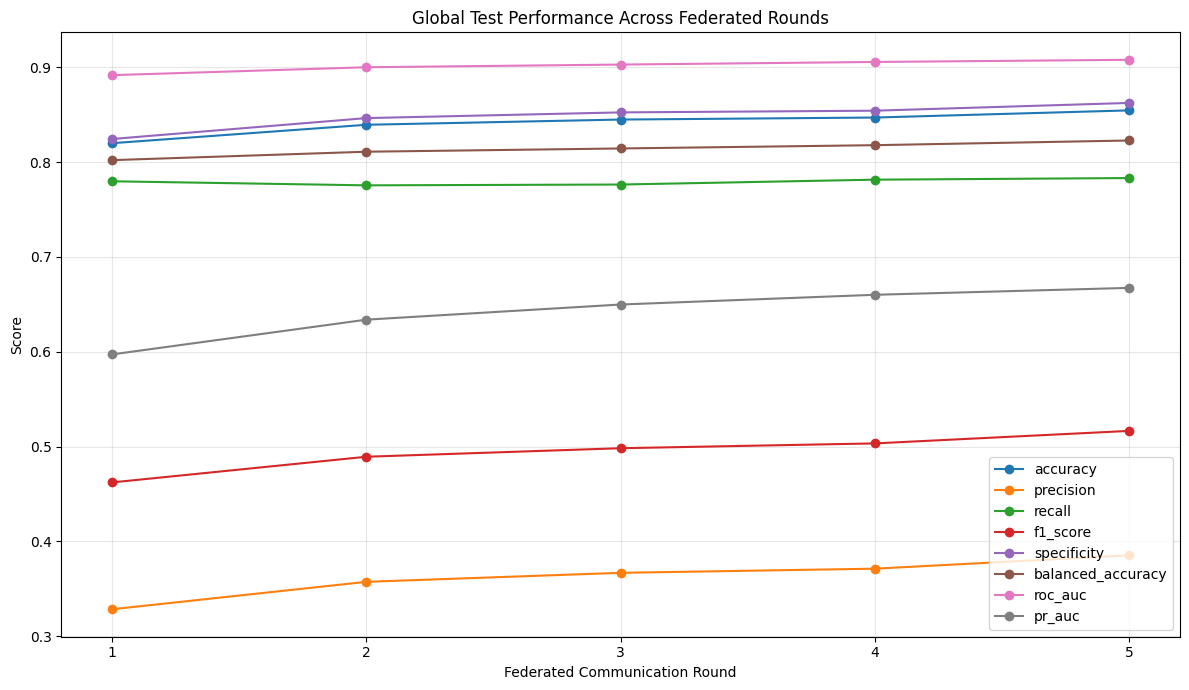

In [83]:
metrics_to_plot = [
    "accuracy",
    "precision",
    "recall",
    "f1_score",
    "specificity",
    "balanced_accuracy",
    "roc_auc",
    "pr_auc",
]

plt.figure(figsize=(12, 7))
for metric in metrics_to_plot:
    plt.plot(
        federated_results["round"],
        federated_results[metric],
        marker="o",
        label=metric
    )

plt.xlabel("Federated Communication Round")
plt.ylabel("Score")
plt.title("Global Test Performance Across Federated Rounds")
plt.xticks(federated_results["round"])
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


## 15. Client-level heterogeneity

Client metrics are reported descriptively. Because the clients were generated by random partitioning rather than institutional sources, differences must **not** be interpreted as hospital-specific characteristics.


,client_id,num_samples,accuracy,precision,recall,f1_score,specificity,balanced_accuracy,roc_auc,pr_auc
20,client_1,8493,0.8725,0.4372,0.8921,0.5868,0.8703,0.8812,0.9538,0.7671
21,client_2,8493,0.8732,0.4329,0.8852,0.5814,0.8719,0.8785,0.9538,0.7624
22,client_3,8492,0.8606,0.4138,0.8922,0.5653,0.8570,0.8746,0.9517,0.7247
23,client_4,8492,0.8526,0.3971,0.8959,0.5503,0.8477,0.8718,0.9477,0.7474
24,client_5,8492,0.8729,0.4131,0.8696,0.5601,0.8733,0.8714,0.9483,0.7243


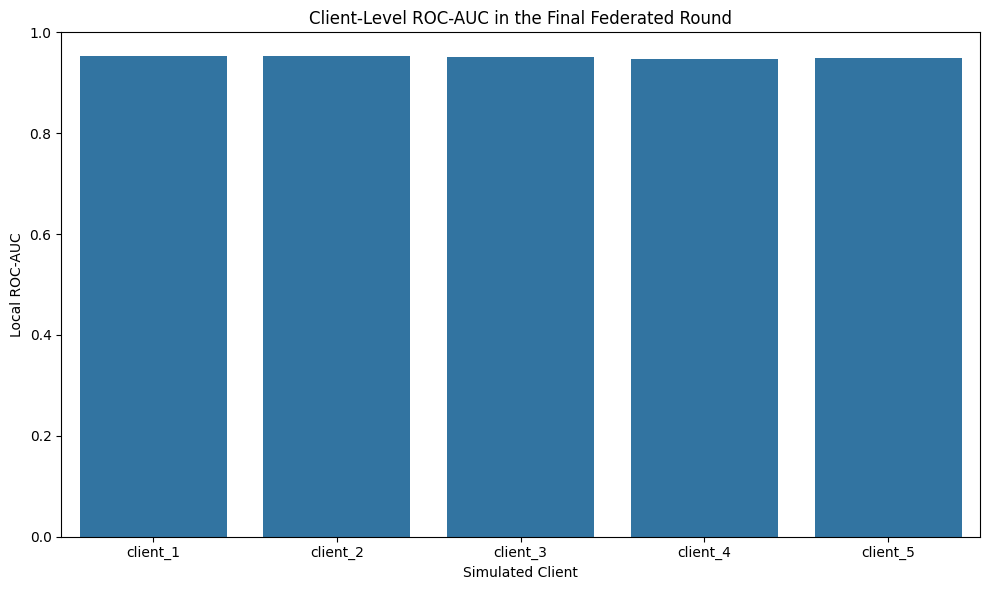

In [84]:
last_round_clients = local_results_df[
    local_results_df["round"] == N_ROUNDS
].copy()

display(
    last_round_clients[
        [
            "client_id", "num_samples", "accuracy",
            "precision", "recall", "f1_score",
            "specificity", "balanced_accuracy", "roc_auc", "pr_auc"
        ]
    ].round(4)
)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=last_round_clients,
    x="client_id",
    y="roc_auc"
)
plt.xlabel("Simulated Client")
plt.ylabel("Local ROC-AUC")
plt.title("Client-Level ROC-AUC in the Final Federated Round")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()


## 16. ROC and Precision–Recall curves for the final federated model

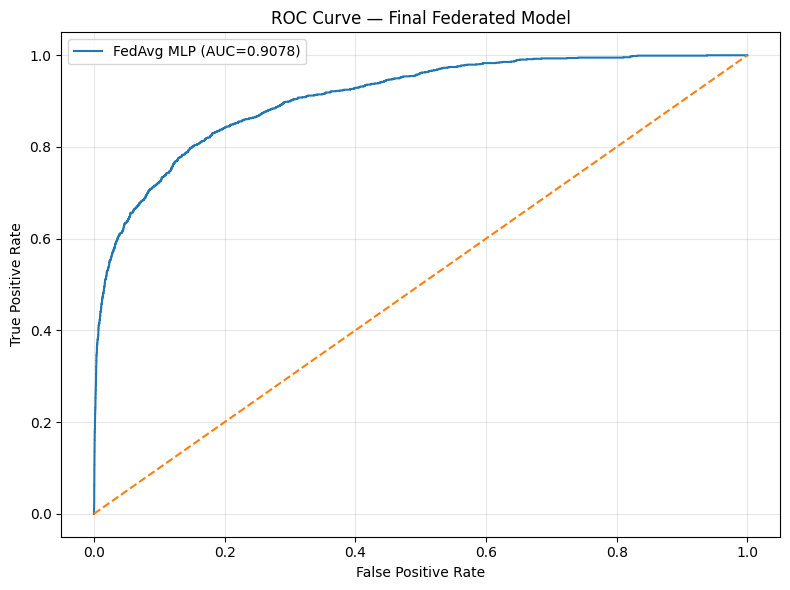

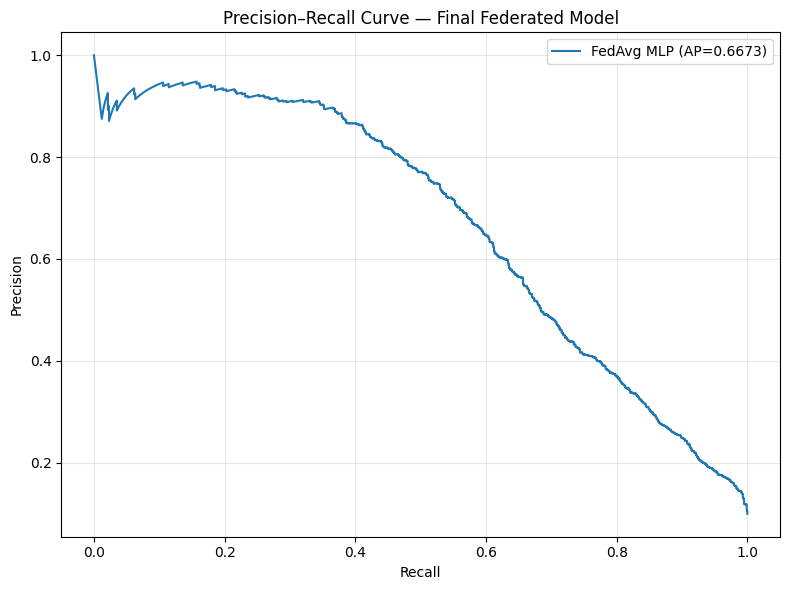

In [85]:
final_fed_prob = predict_proba_torch(server.global_model, X_test)

fpr, tpr, _ = roc_curve(y_test, final_fed_prob)
precision_curve, recall_curve, _ = precision_recall_curve(y_test, final_fed_prob)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f"FedAvg MLP (AUC={roc_auc_score(y_test, final_fed_prob):.4f})")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — Final Federated Model")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 6))
plt.plot(
    recall_curve,
    precision_curve,
    label=f"FedAvg MLP (AP={average_precision_score(y_test, final_fed_prob):.4f})"
)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curve — Final Federated Model")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## 17. Confusion matrix and classification report

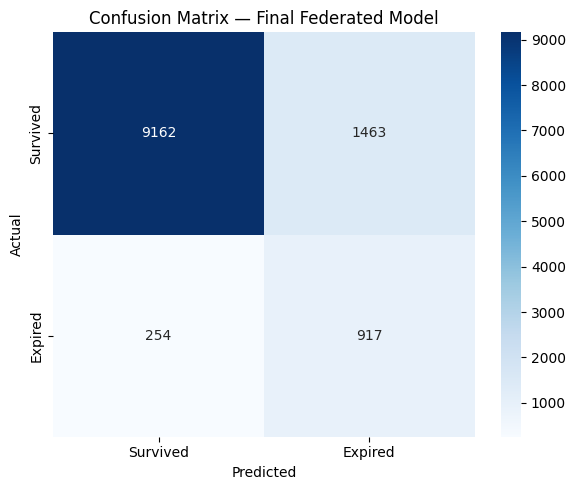

              precision    recall  f1-score   support

    Survived     0.9730    0.8623    0.9143     10625
     Expired     0.3853    0.7831    0.5165      1171

    accuracy                         0.8544     11796
   macro avg     0.6792    0.8227    0.7154     11796
weighted avg     0.9147    0.8544    0.8748     11796



In [86]:
final_pred = (final_fed_prob >= CLASSIFICATION_THRESHOLD).astype(int)

cm = confusion_matrix(y_test.astype(int), final_pred, labels=[0, 1])

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Survived", "Expired"],
    yticklabels=["Survived", "Expired"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix — Final Federated Model")
plt.tight_layout()
plt.show()

print(
    classification_report(
        y_test.astype(int),
        final_pred,
        target_names=["Survived", "Expired"],
        digits=4,
        zero_division=0
    )
)


## 18. Blockchain integrity and audit summary

The checks below establish whether the local blockchain data structure remains internally hash-consistent.

This is an **integrity check of the prototype**, not an empirical proof of Byzantine fault tolerance, adversarial robustness, or tamper-proof security.


In [87]:
print("Blockchain summary:")
for k, v in blockchain.summary().items():
    print(f"{k:20s}: {v}")

print("\nBlock-by-block audit:")
for block in blockchain.chain:
    print(
        f"Block {block.index}: "
        f"hash={block.hash[:16]}..., "
        f"previous={block.previous_hash[:16]}..."
    )


Blockchain summary:
blocks              : 6
transactions        : 25
valid               : True
difficulty          : 2

Block-by-block audit:
Block 0: hash=eb883ac440b4ba28..., previous=0...
Block 1: hash=00735727b99d5d8d..., previous=eb883ac440b4ba28...
Block 2: hash=001060343feb283e..., previous=00735727b99d5d8d...
Block 3: hash=002cf07a74cd1036..., previous=001060343feb283e...
Block 4: hash=000c296f632891a1..., previous=002cf07a74cd1036...
Block 5: hash=004f8b216dc310a8..., previous=000c296f632891a1...


## 19. Optional integrity-tampering demonstration

This cell deliberately changes a stored block after mining and checks whether the chain validator detects the modification.

It is an integrity demonstration only.


In [88]:
# Work on a deep copy so the main experimental chain is preserved.
tampered_chain = copy.deepcopy(blockchain)

if len(tampered_chain.chain) > 1:
    original_validity = tampered_chain.is_chain_valid()

    # Block.data is a list of transaction dictionaries.
    # Modify one existing transaction to simulate tampering.
    if isinstance(tampered_chain.chain[1].data, list) and tampered_chain.chain[1].data:
        tampered_chain.chain[1].data[0]["TAMPER_TEST"] = "modified"
    elif isinstance(tampered_chain.chain[1].data, dict):
        tampered_chain.chain[1].data["TAMPER_TEST"] = "modified"
    else:
        tampered_chain.chain[1].data = {"TAMPER_TEST": "modified"}

    after_tampering = tampered_chain.is_chain_valid()

    print("Before tampering:", original_validity)
    print("After tampering :", after_tampering)
    print("Tampering detected:", original_validity and not after_tampering)
else:
    print("Tampering test skipped: blockchain contains only the genesis block.")


Before tampering: True
After tampering : False
Tampering detected: True


## 20. Final reproducibility summary

The final outputs required for Section 4 should be generated from:
- `centralized_vs_federated_results.csv`
- `federated_round_results.csv`
- `federated_client_results.csv`

Do **not** copy numerical values into the manuscript manually before this notebook has been executed successfully from start to finish.


In [89]:
print('='*90); print('FINAL EXPERIMENT SUMMARY'); print('='*90)
print('\nExperimental scope:',PREDICTION_SCOPE)
print('\nCentralized MLP:'); print_metrics(centralized_metrics)
print('\nFinal Federated MLP (FedAvg):'); print_metrics({k:final_fed[k] for k in ['accuracy','precision','recall','f1_score','specificity','balanced_accuracy','roc_auc','pr_auc']})
print('\nBlockchain:'); print(blockchain.summary())
print('\nPatient grouping column:',GROUP_COLUMN)
if GROUP_COLUMN is None: print('[WARNING] Patient-level independence was not established.')
print('\nFiles saved:'); print(' - centralized_vs_federated_results.csv'); print(' - federated_round_results.csv'); print(' - federated_client_results.csv')


FINAL EXPERIMENT SUMMARY

Experimental scope: retrospective_encounter_level_mortality_classification

Centralized MLP:
accuracy            : 0.8688
precision           : 0.4144
recall              : 0.7797
f1_score            : 0.5412
specificity         : 0.8786
balanced_accuracy   : 0.8291
roc_auc             : 0.9139
pr_auc              : 0.6937

Final Federated MLP (FedAvg):
accuracy            : 0.8544
precision           : 0.3853
recall              : 0.7831
f1_score            : 0.5165
specificity         : 0.8623
balanced_accuracy   : 0.8227
roc_auc             : 0.9078
pr_auc              : 0.6673

Blockchain:
{'blocks': 6, 'transactions': 25, 'valid': True, 'difficulty': 2}

Patient grouping column: None
[WARNING] Patient-level independence was not established.

Files saved:
 - centralized_vs_federated_results.csv
 - federated_round_results.csv
 - federated_client_results.csv


## 20. Interpretation guardrails for the manuscript

Supported by this experiment: empirical centralized-vs-FedAvg comparison; round-wise global-model performance; descriptive simulated-client results; prototype hash-chain integrity and artificial tampering detection.

Not established by this experiment: clinical deployment readiness; patient-level generalization when no patient ID is available; first-24/48-hour prediction; secure aggregation; differential privacy; malicious-server resistance; Hyperledger Fabric/PBFT; Byzantine fault tolerance; formal tamper-proof security.


In [90]:
## 21. Final methodological validation checklist
checks={'target_is_binary':set(df[TARGET].unique()).issubset({0,1}),'preprocessing_row_alignment':X_train.shape[0]==len(y_train) and X_val.shape[0]==len(y_val) and X_test.shape[0]==len(y_test),'identifier_exclusion':not any(c in X_train_df.columns for c in PRESENT_IDENTIFIER_COLUMNS),'same_global_pos_weight':USE_GLOBAL_POS_WEIGHT,'fedavg_has_multiple_rounds':len(federated_results)==N_ROUNDS,'blockchain_valid_all_rounds':bool(federated_results['blockchain_valid'].all()),'comparison_same_test_set':True}
checks['patient_group_disjointness']=False if GROUP_COLUMN is None else (set(train_df[GROUP_COLUMN]).isdisjoint(set(test_df[GROUP_COLUMN])) and set(train_df[GROUP_COLUMN]).isdisjoint(set(val_df[GROUP_COLUMN])) and set(val_df[GROUP_COLUMN]).isdisjoint(set(test_df[GROUP_COLUMN])))
print('='*80); print('FINAL VALIDATION'); print('='*80)
for name,passed in checks.items(): print(f"{name:35s}: {'PASS' if passed else 'FAIL / NOT ESTABLISHED'}")


FINAL VALIDATION
target_is_binary                   : PASS
preprocessing_row_alignment        : PASS
identifier_exclusion               : PASS
same_global_pos_weight             : PASS
fedavg_has_multiple_rounds         : PASS
blockchain_valid_all_rounds        : PASS
comparison_same_test_set           : PASS
patient_group_disjointness         : FAIL / NOT ESTABLISHED
